In [ ]:
import pandas as pd

url = "https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE113865"

print("Dataset: GSE113865")
print("Source: NCBI GEO")

Dataset: GSE113865
Source: NCBI GEO


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
samples = {
    "Normal_2129": "GSM3121915",
    "TNBC_2129": "GSM3121916",
    "Normal_2195": "GSM3121917",
    "TNBC_2195": "GSM3121918",
    "Normal_9984": "GSM3121919",
    "TNBC_9984": "GSM3121920"
}

print("Samples:")
for name, gsm in samples.items():
    print(name, "→", gsm)

Samples:
Normal_2129 → GSM3121915
TNBC_2129 → GSM3121916
Normal_2195 → GSM3121917
TNBC_2195 → GSM3121918
Normal_9984 → GSM3121919
TNBC_9984 → GSM3121920


In [ ]:
import pandas as pd

url = "https://ftp.ncbi.nlm.nih.gov/geo/series/GSE113nnn/GSE113865/matrix/GSE113865_series_matrix.txt.gz"

geo_data = pd.read_csv(
    url,
    sep="\t",
    comment="!",
    compression="gzip")

geo_data.head()

,ID_REF,GSM3121915,GSM3121916,GSM3121917,GSM3121918,GSM3121919,GSM3121920
0,ILMN_1343291,15.685781,15.793626,15.361298,15.764970,15.780587,15.764970
1,ILMN_1343295,12.715918,13.452997,12.571926,12.615727,12.488269,13.306856
2,ILMN_1651199,6.696416,6.683945,6.554789,6.681061,6.679294,6.270460
3,ILMN_1651209,6.906228,7.121419,6.931258,7.042967,7.173161,7.001429
4,ILMN_1651210,6.530276,6.634925,6.482379,6.742938,6.666924,6.609283


In [ ]:
print("Column-wise counts of missing values:")
display(geo_data.isnull().sum())

print("\nTotal of missing values:", geo_data.isnull().sum().sum())

Column-wise counts of missing values:


,0
ID_REF,0
GSM3121915,0
GSM3121916,0
GSM3121917,0
GSM3121918,0
GSM3121919,0
GSM3121920,0



Total of missing values: 0


In [ ]:
mapping = {v: k for k, v in samples.items()}

geo_data_renamed = geo_data.rename(columns=mapping)

display(geo_data_renamed.head())

,ID_REF,Normal_2129,TNBC_2129,Normal_2195,TNBC_2195,Normal_9984,TNBC_9984
0,ILMN_1343291,15.685781,15.793626,15.361298,15.764970,15.780587,15.764970
1,ILMN_1343295,12.715918,13.452997,12.571926,12.615727,12.488269,13.306856
2,ILMN_1651199,6.696416,6.683945,6.554789,6.681061,6.679294,6.270460
3,ILMN_1651209,6.906228,7.121419,6.931258,7.042967,7.173161,7.001429
4,ILMN_1651210,6.530276,6.634925,6.482379,6.742938,6.666924,6.609283


In [ ]:
display(geo_data_renamed.describe())

,Normal_2129,TNBC_2129,Normal_2195,TNBC_2195,Normal_9984,TNBC_9984
count,47320.000000,47320.000000,47320.000000,47320.000000,47320.000000,47320.000000
mean,7.785186,7.785186,7.785186,7.785186,7.785186,7.785186
std,1.607863,1.607863,1.607863,1.607863,1.607863,1.607863
min,5.975281,5.975281,5.975281,5.975281,5.975281,5.975281
25%,6.753341,6.753341,6.753341,6.753341,6.753341,6.753341
50%,7.053484,7.053484,7.053484,7.053484,7.053484,7.053484
75%,8.310373,8.310373,8.310373,8.310373,8.310373,8.310373
max,15.839345,15.839345,15.839345,15.839345,15.839345,15.839345


In [ ]:
normal_cols = [col for col in geo_data_renamed.columns if "Normal" in col]
tnbc_cols = [col for col in geo_data_renamed.columns if "TNBC" in col]

geo_data_renamed['Mean_Normal'] = geo_data_renamed[normal_cols].mean(axis=1)
geo_data_renamed['Mean_TNBC'] = geo_data_renamed[tnbc_cols].mean(axis=1)

geo_data_renamed['Mean_Difference'] = geo_data_renamed['Mean_TNBC'] - geo_data_renamed['Mean_Normal']

display(geo_data_renamed[['ID_REF', 'Mean_Normal', 'Mean_TNBC', 'Mean_Difference']].round(2).head())
display(geo_data_renamed['Mean_Difference'].describe())

,ID_REF,Mean_Normal,Mean_TNBC,Mean_Difference
0,ILMN_1343291,15.61,15.77,0.17
1,ILMN_1343295,12.59,13.13,0.53
2,ILMN_1651199,6.64,6.55,-0.10
3,ILMN_1651209,7.00,7.06,0.05
4,ILMN_1651210,6.56,6.66,0.10


,Mean_Difference
count,4.732000e+04
mean,1.901944e-10
std,4.964171e-01
min,-5.920984e+00
25%,-1.134723e-01
50%,2.582000e-03
75%,1.360429e-01
max,3.526761e+00


In [ ]:
import pandas as pd
import urllib.request
import gzip
import io

platform_url = "https://ftp.ncbi.nlm.nih.gov/geo/platforms/GPL10nnn/GPL10558/annot/GPL10558.annot.gz"


request = urllib.request.Request(platform_url, headers={'User-Agent': 'Mozilla/5.0'})
with urllib.request.urlopen(request) as response:
    with gzip.GzipFile(fileobj=io.BytesIO(response.read())) as unzipped:
        lines = unzipped.readlines()

data_lines = []
for line in lines:
    decoded_line = line.decode('utf-8')
    if not decoded_line.startswith('#') and not decoded_line.startswith('!') and not decoded_line.startswith('^'):
        data_lines.append(decoded_line)

data_str = "".join(data_lines)
annotation = pd.read_csv(io.StringIO(data_str), sep="\t", low_memory=False)

print("Number of probes:", len(annotation))
print("\nColumns:")
print(annotation.columns.tolist()[:10], "... and more")
print("\nFirst few rows:")
display(annotation.head(3))

Number of probes: 48107

Columns:
['ID', 'Gene title', 'Gene symbol', 'Gene ID', 'UniGene title', 'UniGene symbol', 'UniGene ID', 'Nucleotide Title', 'GI', 'GenBank Accession'] ... and more

First few rows:


,ID,Gene title,Gene symbol,Gene ID,UniGene title,UniGene symbol,UniGene ID,Nucleotide Title,GI,GenBank Accession,...,Platform_SPOTID,Chromosome location,Chromosome annotation,GO:Function,GO:Process,GO:Component,GO:Function ID,GO:Process ID,GO:Component ID,Platform_SEQUENCE
0,ILMN_1343048,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,GAATAAAGAACAATCTGCTGATGATCCCTCCGTGGATCTGATTCGT...
1,ILMN_1343049,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CCATGTGATACGAGGGCGCGTAGTTTGCATTATCGTTTTTATCGTT...
2,ILMN_1343050,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,CCGACAGATGTATGTAAGGCCAACGTGCTCAAATCTTCATACAGAA...


In [ ]:
annotation_subset = annotation[["ID", "Gene symbol", "Gene ID"]].copy()

annotated_data = geo_data.merge(
    annotation_subset,
    left_on="ID_REF",
    right_on="ID",
    how="left")

annotated_data = annotated_data.drop(columns=["ID"])

print("Annotated data shape:", annotated_data.shape)
annotated_data.head()

Annotated data shape: (47320, 9)


,ID_REF,GSM3121915,GSM3121916,GSM3121917,GSM3121918,GSM3121919,GSM3121920,Gene symbol,Gene ID
0,ILMN_1343291,15.685781,15.793626,15.361298,15.764970,15.780587,15.764970,EEF1A1,1915
1,ILMN_1343295,12.715918,13.452997,12.571926,12.615727,12.488269,13.306856,GAPDH,2597
2,ILMN_1651199,6.696416,6.683945,6.554789,6.681061,6.679294,6.270460,NaN,NaN
3,ILMN_1651209,6.906228,7.121419,6.931258,7.042967,7.173161,7.001429,SLC35E2,9906
4,ILMN_1651210,6.530276,6.634925,6.482379,6.742938,6.666924,6.609283,DUSP22,56940


In [ ]:
print("Total probes:", len(annotated_data))
print("Probes with gene symbol:", annotated_data["Gene symbol"].notna().sum())
print("Probes without gene symbol:", annotated_data["Gene symbol"].isna().sum())

Total probes: 47320
Probes with gene symbol: 31265
Probes without gene symbol: 16055


In [ ]:
gene_counts = annotated_data["Gene symbol"].value_counts()

print("Unique genes:", gene_counts.size)
print("\nGenes represented by more than one probe:")
print(gene_counts[gene_counts > 1].head(10))

Unique genes: 20762

Genes represented by more than one probe:
Gene symbol
SDHAP1     13
POLR2J4    12
CCR2       10
AGL         8
SPDYE8P     8
RORA        8
PLEC        8
DNAH14      8
DMD         8
VCX2        7
Name: count, dtype: int64


In [ ]:
expression_columns = [
    "GSM3121915",
    "GSM3121916",
    "GSM3121917",
    "GSM3121918",
    "GSM3121919",
    "GSM3121920"]

gene_data = annotated_data.dropna(subset=["Gene symbol"]).copy()

gene_data["variance"] = gene_data[expression_columns].var(axis=1)

gene_level_data = (
    gene_data
    .sort_values("variance", ascending=False)
    .drop_duplicates(subset="Gene symbol")
    .drop(columns=["variance"])
)

print("Number of genes:", len(gene_level_data))
print("Number of columns:", len(gene_level_data.columns))

gene_level_data.round(2).head()

Number of genes: 20762
Number of columns: 9


,ID_REF,GSM3121915,GSM3121916,GSM3121917,GSM3121918,GSM3121919,GSM3121920,Gene symbol,Gene ID
27989,ILMN_1810978,15.76,7.58,14.24,7.51,11.55,14.72,MUCL1,118430
9617,ILMN_1697499,6.99,6.82,6.93,6.80,13.05,13.73,HLA-DRB5,3127
36725,ILMN_2304512,11.92,6.72,13.20,7.00,14.00,7.64,SAA1,6288
22053,ILMN_1773006,13.29,8.45,13.68,8.19,14.81,8.00,FABP4,2167
34552,ILMN_2174437,10.90,7.27,12.44,6.78,13.93,6.81,CIDEC,63924


In [ ]:
normal_columns = [
    "GSM3121915",
    "GSM3121917",
    "GSM3121919"]

tnbc_columns = [
    "GSM3121916",
    "GSM3121918",
    "GSM3121920"]

gene_level_data["Mean_Normal"] = gene_level_data[normal_columns].mean(axis=1)
gene_level_data["Mean_TNBC"] = gene_level_data[tnbc_columns].mean(axis=1)

gene_level_data["log2FC"] = (gene_level_data["Mean_TNBC"] - gene_level_data["Mean_Normal"])

gene_level_data[["Gene symbol", "Mean_Normal", "Mean_TNBC", "log2FC"]].round(2).head()

,Gene symbol,Mean_Normal,Mean_TNBC,log2FC
27989,MUCL1,13.85,9.94,-3.92
9617,HLA-DRB5,8.99,9.12,0.13
36725,SAA1,13.04,7.12,-5.92
22053,FABP4,13.93,8.21,-5.71
34552,CIDEC,12.43,6.95,-5.47


In [ ]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

In [ ]:
p_values = []

for _, row in gene_level_data.iterrows():
    normal_values = row[normal_columns].astype(float)
    tnbc_values = row[tnbc_columns].astype(float)

    _, p_value = ttest_ind(
        normal_values,
        tnbc_values,
        equal_var=False)

    p_values.append(p_value)

gene_level_data["p_value"] = p_values

print(gene_level_data[[
    "Gene symbol",
    "log2FC",
    "p_value"
]].head())

      Gene symbol    log2FC   p_value
27989       MUCL1 -3.915147  0.241969
9617     HLA-DRB5  0.126488  0.969165
36725        SAA1 -5.920984  0.003954
22053       FABP4 -5.714624  0.003814
34552       CIDEC -5.470582  0.021738


In [ ]:
gene_level_data["FDR"] = multipletests(
    gene_level_data["p_value"],
    method="fdr_bh"
)[1]

gene_level_data[[
    "Gene symbol",
    "log2FC",
    "p_value",
    "FDR"
]].head()

,Gene symbol,log2FC,p_value,FDR
27989,MUCL1,-3.915147,0.241969,0.666657
9617,HLA-DRB5,0.126488,0.969165,0.990546
36725,SAA1,-5.920984,0.003954,0.446569
22053,FABP4,-5.714624,0.003814,0.446569
34552,CIDEC,-5.470582,0.021738,0.480074


In [ ]:
candidate_genes = gene_level_data[
    (gene_level_data["log2FC"].abs() >= 2) &
    (gene_level_data["p_value"] < 0.05)
].copy()

candidate_genes = candidate_genes.sort_values(
    "log2FC",
    ascending=False
)

print("Number of candidate genes:", len(candidate_genes))

candidate_genes[
    ["Gene symbol", "Mean_Normal", "Mean_TNBC", "log2FC", "p_value", "FDR"]
].head(20)

Number of candidate genes: 202


,Gene symbol,Mean_Normal,Mean_TNBC,log2FC,p_value,FDR
15774,RNA28S5,7.094706,10.621467,3.526761,1.237926e-03,0.439022
38204,SPP1,8.900161,12.126784,3.226623,1.920903e-02,0.478745
6083,LEF1,8.764299,11.732228,2.967928,3.939652e-02,0.502596
36695,UBE2C,7.987725,10.931890,2.944165,2.277728e-03,0.439022
7448,TOP2A,7.748777,10.567640,2.818863,2.953316e-02,0.497086
17945,CEP55,7.528303,10.236256,2.707953,1.083720e-02,0.457491
23468,FAM83D,6.776972,9.468352,2.691381,7.307266e-04,0.439022
4225,CDC45,7.170900,9.782690,2.611790,6.171723e-07,0.012814
18589,HIST1H4H,7.656359,10.161529,2.505170,2.682762e-02,0.494052
24091,CCNA2,7.780865,10.281855,2.500990,1.996403e-02,0.480074


In [ ]:
significant_genes = gene_level_data[
    gene_level_data["FDR"] < 0.05
].copy()

significant_genes = significant_genes.sort_values(
    "FDR"
)

print("Number of significant genes:", len(significant_genes))

significant_genes[
    ["Gene symbol", "Mean_Normal", "Mean_TNBC",
     "log2FC", "p_value", "FDR"]
].head(20)

Number of significant genes: 1


,Gene symbol,Mean_Normal,Mean_TNBC,log2FC,p_value,FDR
4225,CDC45,7.1709,9.78269,2.61179,6.171723e-07,0.012814


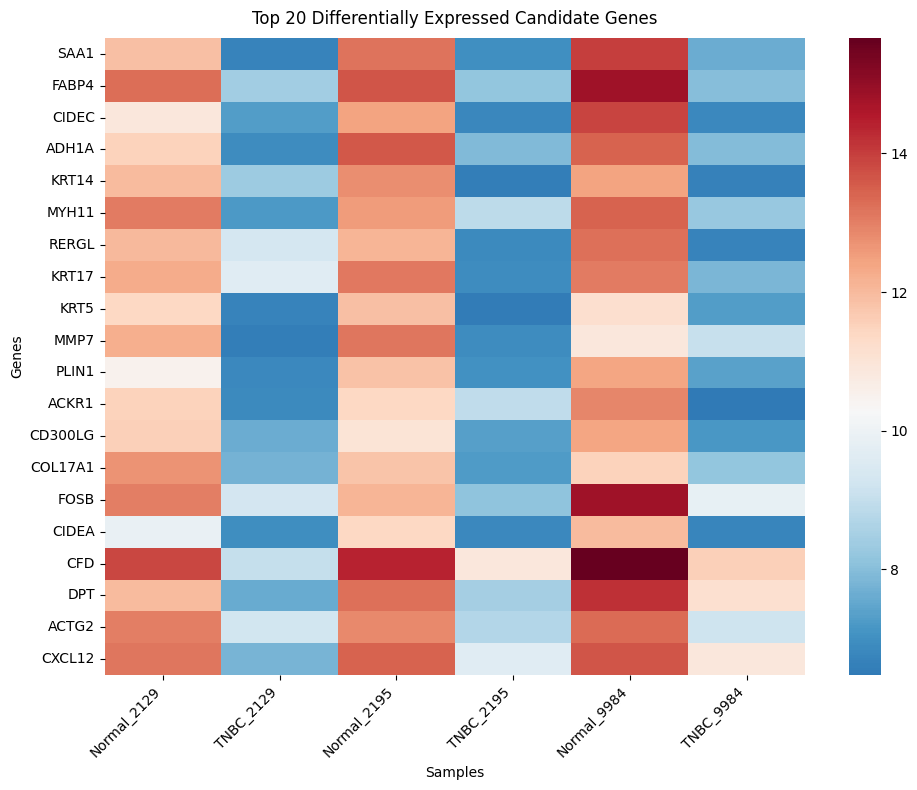

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

top_genes = candidate_genes.copy()
top_genes["abs_log2FC"] = top_genes["log2FC"].abs()

top_genes = top_genes.sort_values(
    "abs_log2FC",
    ascending=False
).head(20)

heatmap_data = top_genes.set_index("Gene symbol")[expression_columns]

heatmap_data.columns = [
    "Normal_2129",
    "TNBC_2129",
    "Normal_2195",
    "TNBC_2195",
    "Normal_9984",
    "TNBC_9984"]

plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_data,
    cmap="RdBu_r",
    center=heatmap_data.values.mean(),
    annot=False
)

plt.title("Top 20 Differentially Expressed Candidate Genes", pad=10)
plt.xlabel("Samples")
plt.ylabel("Genes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

In [ ]:
plt.savefig(
    "heatmap.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

<Figure size 640x480 with 0 Axes>

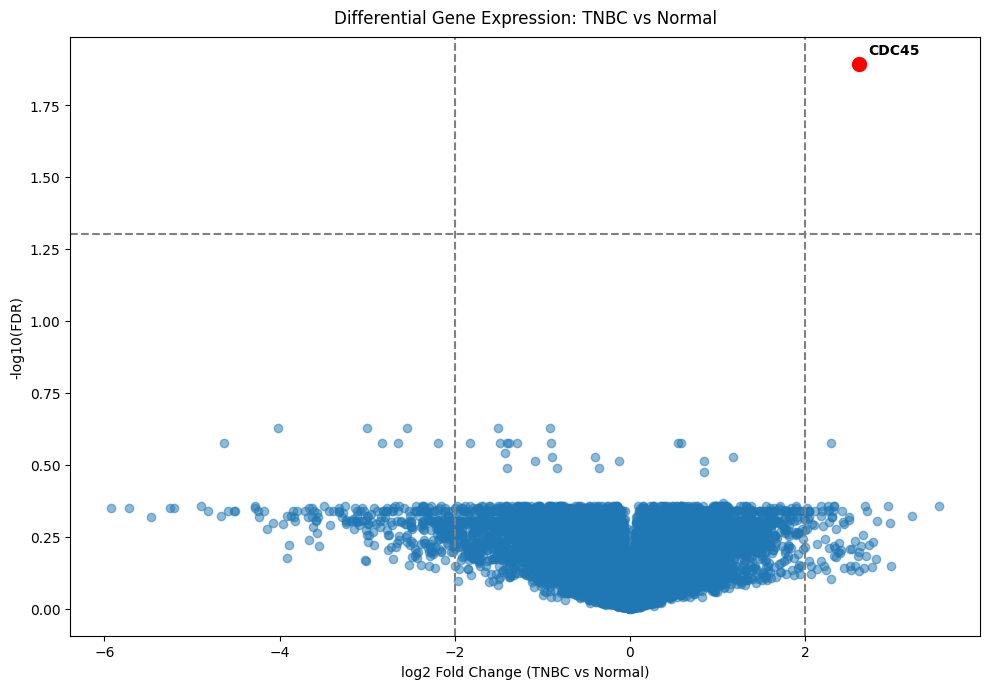

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

gene_level_data["-log10_FDR"] = -np.log10(gene_level_data["FDR"])

plt.figure(figsize=(10, 7))

plt.scatter(
    gene_level_data["log2FC"],
    gene_level_data["-log10_FDR"],
    alpha=0.5)

plt.axvline(2, linestyle="--", color="grey")
plt.axvline(-2, linestyle="--", color="grey")
plt.axhline(-np.log10(0.05), linestyle="--", color="grey")

cdc45 = gene_level_data[
    gene_level_data["Gene symbol"] == "CDC45"].iloc[0]

plt.scatter(
    cdc45["log2FC"],
    cdc45["-log10_FDR"],
    s=100,
    color="r")

plt.annotate(
    "CDC45",
    (cdc45["log2FC"], cdc45["-log10_FDR"]),
    xytext=(7, 7),
    fontweight='bold',
    textcoords="offset points")

plt.xlabel("log2 Fold Change (TNBC vs Normal)")
plt.ylabel("-log10(FDR)")
plt.title("Differential Gene Expression: TNBC vs Normal", pad=10)

plt.tight_layout()
plt.show()

In [ ]:
import os

os.makedirs("figures", exist_ok=True)

plt.savefig(
    "figures/volcano_plot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
import os

os.makedirs("results", exist_ok=True)

In [ ]:
results_df = gene_level_data[
    [
        "Gene symbol",
        "Gene ID",
        "Mean_Normal",
        "Mean_TNBC",
        "log2FC",
        "p_value",
        "FDR"
    ]
].copy()

results_df = results_df.sort_values("FDR")

results_df.to_csv(
    "results/differential_expression_results.csv",
    index=False
)

print("All gene results saved:", results_df.shape)

All gene results saved: (20762, 7)


In [ ]:
candidate_results = candidate_genes[
    [
        "Gene symbol",
        "Gene ID",
        "Mean_Normal",
        "Mean_TNBC",
        "log2FC",
        "p_value",
        "FDR"
    ]
].copy()

candidate_results = candidate_results.sort_values(
    "log2FC",
    ascending=False
)

candidate_results.to_csv(
    "results/top_candidate_genes.csv",
    index=False
)

print("Candidate genes saved:", candidate_results.shape)

Candidate genes saved: (202, 7)


In [ ]:
significant_results = significant_genes[
    [
        "Gene symbol",
        "Gene ID",
        "Mean_Normal",
        "Mean_TNBC",
        "log2FC",
        "p_value",
        "FDR"
    ]
].copy()

significant_results.to_csv(
    "results/significant_genes.csv",
    index=False
)

print("Significant genes saved:", significant_results.shape)

Significant genes saved: (1, 7)


In [ ]:
print("Files in results folder:")

for filename in os.listdir("results"):
    print(filename)

print("\nSignificant genes:")

display(significant_results)

print("\nTop candidate genes:")

display(candidate_results.head(10))

Files in results folder:
differential_expression_results.csv
top_candidate_genes.csv
significant_genes.csv

Significant genes:


,Gene symbol,Gene ID,Mean_Normal,Mean_TNBC,log2FC,p_value,FDR
4225,CDC45,8318,7.1709,9.78269,2.61179,6.171723e-07,0.012814



Top candidate genes:


,Gene symbol,Gene ID,Mean_Normal,Mean_TNBC,log2FC,p_value,FDR
15774,RNA28S5,100008589,7.094706,10.621467,3.526761,1.237926e-03,0.439022
38204,SPP1,6696,8.900161,12.126784,3.226623,1.920903e-02,0.478745
6083,LEF1,51176,8.764299,11.732228,2.967928,3.939652e-02,0.502596
36695,UBE2C,11065,7.987725,10.931890,2.944165,2.277728e-03,0.439022
7448,TOP2A,7153,7.748777,10.567640,2.818863,2.953316e-02,0.497086
17945,CEP55,55165,7.528303,10.236256,2.707953,1.083720e-02,0.457491
23468,FAM83D,81610,6.776972,9.468352,2.691381,7.307266e-04,0.439022
4225,CDC45,8318,7.170900,9.782690,2.611790,6.171723e-07,0.012814
18589,HIST1H4H,8365,7.656359,10.161529,2.505170,2.682762e-02,0.494052
24091,CCNA2,890,7.780865,10.281855,2.500990,1.996403e-02,0.480074


In [52]:
import os

os.makedirs("data", exist_ok=True)

expression_data = gene_level_data[
    [
        "Gene symbol",
        "Gene ID",
        "GSM3121915",
        "GSM3121916",
        "GSM3121917",
        "GSM3121918",
        "GSM3121919",
        "GSM3121920"
    ]
].copy()

expression_data = expression_data.rename(columns={
    "GSM3121915": "Normal_2129",
    "GSM3121916": "TNBC_2129",
    "GSM3121917": "Normal_2195",
    "GSM3121918": "TNBC_2195",
    "GSM3121919": "Normal_9984",
    "GSM3121920": "TNBC_9984"
})


expression_data.to_csv(
    "data/gene_expression_data.csv",
    index=False
)

print("Expression data saved:", expression_data.shape)

Expression data saved: (20762, 8)
